In [1]:
import sys
from pathlib import Path

package_root = str(Path.cwd().parent)
if package_root not in sys.path:
    sys.path.append(package_root)

In [2]:
from __future__ import annotations
import pandas as pd 
import json
from typing import Dict, List, Tuple, Set
from pathlib import Path
from collections.abc import Iterable
import matplotlib.pyplot as plt
import seaborn as sns
import os 
import time
import re
import numpy as np
from copy import deepcopy
from itertools import combinations
from datetime import datetime
from typing import Any
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
import time
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from joblib import Parallel, delayed


In [3]:
pd.set_option("display.max_colwidth", None)

In [4]:
DATASET_FOLDER = "../../../dataset/processed-data"
DEVICE_MAPPING_FOLDER = DATASET_FOLDER + "/device-mapping"
DATASET1 = "dataset1"
DATASET2 = "dataset2"
DATASET3 = "dataset3"


DEVICE_TO_BE_INCLUDE_1 = f"{DATASET_FOLDER}/device-mapping/{DATASET1}/device_to_be_include.json"
DEVICE_TO_BE_INCLUDE_2 = f"{DATASET_FOLDER}/device-mapping/{DATASET2}/device_to_be_include.json"
DEVICE_TO_BE_INCLUDE_3 = f"{DATASET_FOLDER}/device-mapping/{DATASET3}/device_to_be_include.json"  

PERFORMANCE_EXPORT_FOLDER = "./performance-with-different-dataset"

FEATURES_FOLDER_1 = f"{DATASET1}-feature-window"
FEATURES_FOLDER_2 = f"{DATASET2}-feature-window"
FEATURES_FOLDER_3 = f"{DATASET3}-feature-window"
DATASET_NAME = {FEATURES_FOLDER_1: "UNSW16", FEATURES_FOLDER_2: "FIT21", FEATURES_FOLDER_3: "YT18"}

FEATURE_FILE = "data.parquet"
FOLD_METADATA_FILE = "training_and_validation_fold.json" 

In [5]:
all_windows = [2, 4, 8, 16, 32, 64, 128, 256]
while all_windows[-1] < 10800:
    all_windows.append(all_windows[-1] + 256)

len(all_windows)

50

In [6]:
device_dict_1 = {}
with open(DEVICE_TO_BE_INCLUDE_1, "r") as f:
    device_dict_1 = json.load(f)

In [7]:
device_dict_2 = {}
with open(DEVICE_TO_BE_INCLUDE_2, "r") as f:
    device_dict_2 = json.load(f)

In [8]:
device_dict_3 = {}
with open(DEVICE_TO_BE_INCLUDE_3, "r") as f:
    device_dict_3 = json.load(f)

In [9]:
WINDOW_SECONDS = 60
ALL_FEATURES = [
    "outgoing_packet_count",
    "outgoing_total_bytes",
    "incoming_packet_count",
    "incoming_total_bytes",
    "aggregated_packet_count",
    "aggregated_total_bytes",
    "idle_time",
]

LABEL_COLUMN = "is_iot_device"
KSPLITS = 5
RANDOM_SEED = 42
# Set to 1 for serial execution or 3 if you have sufficient memory.
N_JOBS = 2


In [10]:
def get_all_devices(list_of_devices: List[str]) -> Set[str]:
    return set(list_of_devices)
# def drop_router(list_of_devices: List[str]) -> Set[str]:
#     router_devices = set(["14:cc:20:51:33:ea"])
#     return set(list_of_devices) - router_devices
# def drop_router_and_hub(list_of_devices: List[str]) -> Set[str]:
#     router_devices = set(["14:cc:20:51:33:ea"])
#     hub_devices = set(["d0:52:a8:00:67:5e","44:65:0d:56:cc:d3"])
#     return set(list_of_devices) - router_devices - hub_devices
# def drop_router_and_camera(list_of_devices: List[str]) -> Set[str]:
#     router_devices = set(["14:cc:20:51:33:ea"])
#     camera_devices = set(["70:ee:50:18:34:43","30:8c:fb:2f:e4:b2","00:16:6c:ab:6b:88","f4:f2:6d:93:51:f1","00:62:6e:51:27:2e"])
#     return set(list_of_devices) - router_devices - camera_devices

dropping_strategies = {
    "no_dropping": get_all_devices,
    # "drop_router": drop_router,
    # "drop_router_and_hub": drop_router_and_hub,
    # "drop_router_and_camera": drop_router_and_camera,
}

In [11]:
def label_2_class(features: pd.DataFrame, device_mapping: Dict[str, Dict[str, str]]) -> pd.DataFrame:
    unknown_macs = set(features["mac"]) - set(device_mapping)
    if unknown_macs:
        raise KeyError(f"MAC addresses not found in device_mapping: {unknown_macs}")

    # Dictionary mapping is handled in pandas rather than a Python call per row.
    res = features.copy()
    for column in ("is_iot_device", "device_type", "vendor"):
        mapping = {mac: device_mapping[mac][column] for mac in set(features["mac"])}
        res[column] = res["mac"].map(mapping)
    return res


labeling_strategies = {
    "nonIot-vs-iot": (label_2_class, [0, 1]),
}


In [12]:
def evaluate_device_predictions(
    val_df: pd.DataFrame,
    set_of_devices_to_be_classified: set,
    device_dict: dict,
    label_column: str,
    class_labels: list,
    label_function: callable,
) -> Tuple[dict, pd.DataFrame]:
    expected_devices = set_of_devices_to_be_classified
    actual_devices = set(val_df["mac"].unique())
    if actual_devices != expected_devices:
        missing = expected_devices - actual_devices
        unexpected = actual_devices - expected_devices
        raise ValueError(
            f"Device mismatch.\n"
            f"Missing from validation: {missing}\n"
            f"Unexpected in validation: {unexpected}"
        )
    if val_df["prediction_each_window"].isna().any():
        raise ValueError("prediction_each_window contains missing values.")
    invalid_predictions = set(val_df["prediction_each_window"].unique()) - set(class_labels)
    if invalid_predictions:
        raise ValueError(f"Found predictions not included in class_labels: {invalid_predictions}")

    # Count predictions in one grouped pass; idxmax keeps the first label on ties.
    counts = (
        val_df.groupby(["mac", "prediction_each_window"], observed=True)
        .size()
        .unstack(fill_value=0)
        .reindex(columns=class_labels, fill_value=0)
    )
    evaluation = pd.DataFrame({
        "mac": counts.index,
        "total_predictions": counts.sum(axis=1).to_numpy(),
        "prediction_counts": [dict(zip(class_labels, row)) for row in counts.to_numpy()],
        "aggregated_prediction": counts.idxmax(axis=1).to_numpy(),
    })
    evaluation = label_function(features=evaluation, device_mapping=device_dict)

    invalid_true_labels = set(evaluation[label_column].unique()) - set(class_labels)
    if invalid_true_labels:
        raise ValueError(f"Found true labels not included in class_labels: {invalid_true_labels}")

    accuracy = accuracy_score(evaluation[label_column], evaluation["aggregated_prediction"])
    misclassified_mask = evaluation[label_column] != evaluation["aggregated_prediction"]
    misclassified_devices = evaluation.loc[misclassified_mask, "mac"].to_list()
    evaluation = evaluation.rename(columns={"is_iot_device": "true_label"})
    metrics = {
        "accuracy": accuracy,
        "device_count": len(evaluation),
        "correct_count": (~misclassified_mask).sum(),
        "misclassified_count": misclassified_mask.sum(),
        "misclassified_devices": misclassified_devices,
    }
    return metrics, evaluation


In [13]:
dataset_combos = [[FEATURES_FOLDER_1, FEATURES_FOLDER_2], [FEATURES_FOLDER_1, FEATURES_FOLDER_3],[FEATURES_FOLDER_2, FEATURES_FOLDER_3]]

In [14]:
def create_decision_tree(random_seed: int = 42) -> DecisionTreeClassifier:
    return DecisionTreeClassifier(
        criterion="gini",
        splitter="best",
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        min_weight_fraction_leaf=0.0,
        max_features=None,
        max_leaf_nodes=None,
        min_impurity_decrease=0.0,
        class_weight="balanced",
        random_state=random_seed
    )

In [15]:
all_configs = {}
for combo in dataset_combos:
    for dropping_strategy_name, dropping_strategy_func in dropping_strategies.items():
        for labeling_strategy_name, (labeling_strategy_func, all_classes) in labeling_strategies.items():
            trained_dataset = [DATASET_NAME[dataset] for dataset in combo]
            config_key = "_".join(trained_dataset)
            all_configs[config_key] = {}
            all_configs[config_key]["config"] = {
                "feature_combination": ALL_FEATURES,
                "dropping_strategy": dropping_strategy_name,
                "labeling_strategy": labeling_strategy_name
            }
            all_configs[config_key]["metrics_1"] = []
            all_configs[config_key]["evaluations_1"] = []
            all_configs[config_key]["metrics_2"] = []
            all_configs[config_key]["evaluations_2"] = []
            all_configs[config_key]["metrics_3"] = []
            all_configs[config_key]["evaluations_3"] = []
            all_configs[config_key]["config"]["class_labels"] = all_classes.copy()
            
all_configs

{'UNSW16_FIT21': {'config': {'feature_combination': ['outgoing_packet_count',
    'outgoing_total_bytes',
    'incoming_packet_count',
    'incoming_total_bytes',
    'aggregated_packet_count',
    'aggregated_total_bytes',
    'idle_time'],
   'dropping_strategy': 'no_dropping',
   'labeling_strategy': 'nonIot-vs-iot',
   'class_labels': [0, 1]},
  'metrics_1': [],
  'evaluations_1': [],
  'metrics_2': [],
  'evaluations_2': [],
  'metrics_3': [],
  'evaluations_3': []},
 'UNSW16_YT18': {'config': {'feature_combination': ['outgoing_packet_count',
    'outgoing_total_bytes',
    'incoming_packet_count',
    'incoming_total_bytes',
    'aggregated_packet_count',
    'aggregated_total_bytes',
    'idle_time'],
   'dropping_strategy': 'no_dropping',
   'labeling_strategy': 'nonIot-vs-iot',
   'class_labels': [0, 1]},
  'metrics_1': [],
  'evaluations_1': [],
  'metrics_2': [],
  'evaluations_2': [],
  'metrics_3': [],
  'evaluations_3': []},
 'FIT21_YT18': {'config': {'feature_combination

In [16]:
set_all_devices_1 = set(device_dict_1.keys())
set_all_devices_2 = set(device_dict_2.keys())
set_all_devices_3 = set(device_dict_3.keys())

all_devices_set = {FEATURES_FOLDER_1: set_all_devices_1, FEATURES_FOLDER_2: set_all_devices_2, FEATURES_FOLDER_3: set_all_devices_3}

In [17]:
# Read only the columns used downstream. Fold indices still refer to the same rows.
required_columns = ["mac", *ALL_FEATURES]
datasets = (FEATURES_FOLDER_1, FEATURES_FOLDER_2, FEATURES_FOLDER_3)
device_mappings = {
    FEATURES_FOLDER_1: device_dict_1,
    FEATURES_FOLDER_2: device_dict_2,
    FEATURES_FOLDER_3: device_dict_3,
}


def fit_one_pair(dataset_combo, train_arrays, train_labels, val_arrays, val_macs):
    # Concatenation order matches the original pd.concat of the two datasets.
    X_train = np.concatenate([train_arrays[d] for d in dataset_combo], axis=0)
    y_train = np.concatenate([train_labels[d] for d in dataset_combo], axis=0)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)

    model = create_decision_tree(random_seed=RANDOM_SEED)
    model.fit(X_train_scaled, y_train)

    results = []
    for dataset in datasets:
        predictions = pd.DataFrame({
            "mac": val_macs[dataset],
            "prediction_each_window": model.predict(
                scaler.transform(val_arrays[dataset])
            ),
        })
        metrics, evaluation_detail = evaluate_device_predictions(
            val_df=predictions,
            set_of_devices_to_be_classified=all_devices_set[dataset],
            device_dict=device_mappings[dataset],
            label_column=LABEL_COLUMN,
            class_labels=[0, 1],
            label_function=label_2_class,
        )
        results.append((metrics, evaluation_detail))
    return results


for window in all_windows:
    print(f"INFO: Processing for window {window}....", flush=True)
    start_time = time.perf_counter()
    all_features_set = {}
    all_fold_config = {}

    for dataset in datasets:
        data_path = f"{dataset}/{window}/{FEATURE_FILE}"
        fold_path = f"{dataset}/{window}/{FOLD_METADATA_FILE}"
        features = pd.read_parquet(data_path, columns=required_columns)
        all_features_set[dataset] = label_2_class(features, device_mappings[dataset])
        with open(fold_path, "r") as f:
            all_fold_config[dataset] = json.load(f)

    for fold in range(KSPLITS):
        train_arrays, train_labels = {}, {}
        val_arrays, val_macs = {}, {}
        for dataset in datasets:
            data = all_features_set[dataset]
            fold_config = all_fold_config[dataset][fold]
            train = data.iloc[fold_config["train_iloc"]]
            val = data.iloc[fold_config["val_iloc"]]
            train = train.loc[train["mac"].isin(all_devices_set[dataset])]
            val = val.loc[val["mac"].isin(all_devices_set[dataset])]

            train_arrays[dataset] = train[ALL_FEATURES].to_numpy(copy=False)
            train_labels[dataset] = train[LABEL_COLUMN].to_numpy(copy=False)
            val_arrays[dataset] = val[ALL_FEATURES].to_numpy(copy=False)
            val_macs[dataset] = val["mac"].to_numpy(copy=False)

        # Threaded fits release the GIL inside scikit-learn; results remain
        # in dataset_combos order, independent of worker completion order.
        pair_results = Parallel(n_jobs=N_JOBS, prefer="threads")(
            delayed(fit_one_pair)(
                combo, train_arrays, train_labels, val_arrays, val_macs
            )
            for combo in dataset_combos
        )
        for dataset_combo, results in zip(dataset_combos, pair_results):
            config_key = "_".join(DATASET_NAME[d] for d in dataset_combo)
            for suffix, (metrics, evaluation_detail) in enumerate(results, start=1):
                metrics["fold"] = fold
                metrics["window"] = window
                evaluation_detail["fold"] = fold
                evaluation_detail["window"] = window
                all_configs[config_key][f"metrics_{suffix}"].append(metrics)
                all_configs[config_key][f"evaluations_{suffix}"].append(evaluation_detail)

    elapsed_time = time.perf_counter() - start_time
    print(f"\tINFO: Finish window {window} - took {elapsed_time:.2f} seconds", flush=True)


INFO: Processing for window 2....
	INFO: Finish window 2 - took 402.09 seconds
INFO: Processing for window 4....
	INFO: Finish window 4 - took 253.53 seconds
INFO: Processing for window 8....
	INFO: Finish window 8 - took 163.88 seconds
INFO: Processing for window 16....
	INFO: Finish window 16 - took 97.69 seconds
INFO: Processing for window 32....
	INFO: Finish window 32 - took 55.79 seconds
INFO: Processing for window 64....
	INFO: Finish window 64 - took 32.22 seconds
INFO: Processing for window 128....
	INFO: Finish window 128 - took 17.16 seconds
INFO: Processing for window 256....
	INFO: Finish window 256 - took 8.71 seconds
INFO: Processing for window 512....
	INFO: Finish window 512 - took 4.23 seconds
INFO: Processing for window 768....
	INFO: Finish window 768 - took 2.75 seconds
INFO: Processing for window 1024....
	INFO: Finish window 1024 - took 2.03 seconds
INFO: Processing for window 1280....
	INFO: Finish window 1280 - took 1.66 seconds
INFO: Processing for window 1536

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def plot_confusion_matrices(
    evaluations_df,
    config_path,
    suffix,
    class_labels=(1, 2, 3)
):
    y_true = evaluations_df["true_label"]
    y_pred = evaluations_df["aggregated_prediction"]

    # --------------------------------------------------
    # 1. Raw-count confusion matrix
    # --------------------------------------------------
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=class_labels
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_labels
    )

    disp.plot(
        values_format="d"
    )

    plt.title(f"Device-Level Confusion Matrix - {suffix}")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.tight_layout()

    plt.savefig(
        f"{config_path}/confusion_matrix_{suffix}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()


    # --------------------------------------------------
    # 2. Normalized confusion matrix
    # --------------------------------------------------
    cm_normalized = confusion_matrix(
        y_true,
        y_pred,
        labels=class_labels,
        normalize="true"
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm_normalized,
        display_labels=class_labels
    )

    disp.plot(
        values_format=".2f"
    )

    plt.title(f"Normalized Device-Level Confusion Matrix - {suffix}")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.tight_layout()

    plt.savefig(
        f"{config_path}/confusion_matrix_normalized_{suffix}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

In [19]:
def save_metric_and_plotting(config_path: str, metrics_df: pd.DataFrame, evaluations_df: pd.DataFrame, suffix: str, all_configs: dict) -> None:
    Path(config_path).mkdir(parents=True, exist_ok=True)
    # Write these two config into csv files
    metrics_df.to_csv(f"{config_path}/performance_{suffix}.csv", index=False)
    evaluations_df.to_csv(f"{config_path}/detail_performance_{suffix}.csv", index=False)
    with open(f"{config_path}/config.json", "w") as f:
        json.dump(
            all_configs[Path(config_path).name]["config"],
            f,
            indent=4
        )

    accuracy_summary = (
        metrics_df
        .groupby("window")["accuracy"]
        .agg(
            avg_accuracy="mean",
            min_accuracy="min",
            max_accuracy="max"
        )
        .reset_index()
        .sort_values("window")
    )

    plt.figure(figsize=(10, 6))

    # Average accuracy
    plt.plot(
        accuracy_summary["window"],
        accuracy_summary["avg_accuracy"],
        marker="o",
        label="Average Accuracy"
    )

    # Min / Max accuracy
    plt.plot(
        accuracy_summary["window"],
        accuracy_summary["min_accuracy"],
        linestyle="--",
        label="Min Accuracy"
    )

    plt.plot(
        accuracy_summary["window"],
        accuracy_summary["max_accuracy"],
        linestyle="--",
        label="Max Accuracy"
    )

    # Shade the min-max range
    plt.fill_between(
        accuracy_summary["window"],
        accuracy_summary["min_accuracy"],
        accuracy_summary["max_accuracy"],
        alpha=0.2
    )

    plt.xlabel("Window Size")
    plt.ylabel("Accuracy")
    plt.title(f"Accuracy vs Window Size for config={Path(config_path).name}-{suffix}")
    
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plot_path = f"{config_path}/accuracy_vs_window_size_{suffix}.png"
    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plot_confusion_matrices(
        evaluations_df,
        config_path,
        suffix,
        class_labels=all_configs[Path(config_path).name]["config"]["class_labels"]
    )



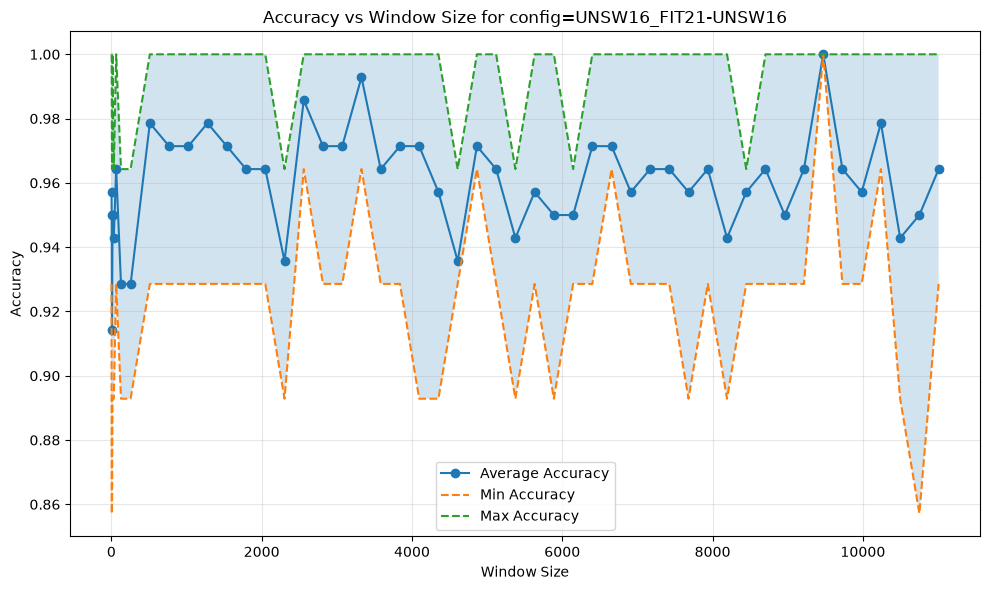

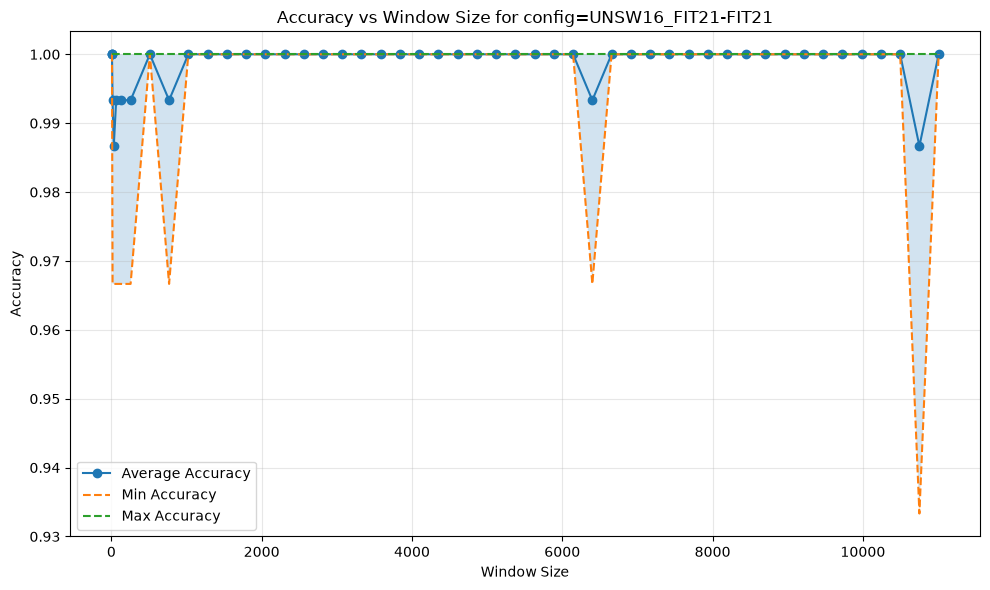

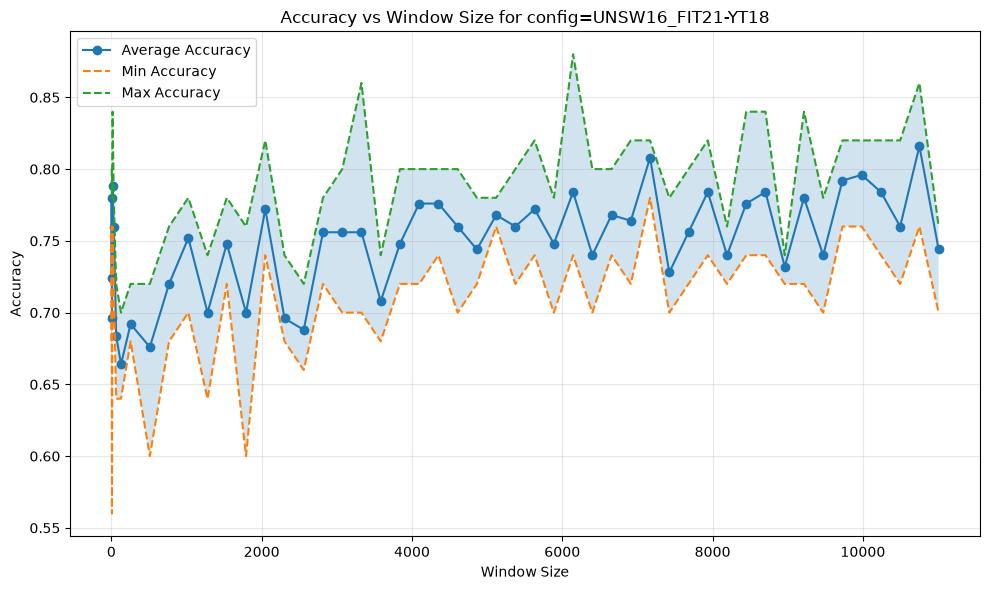

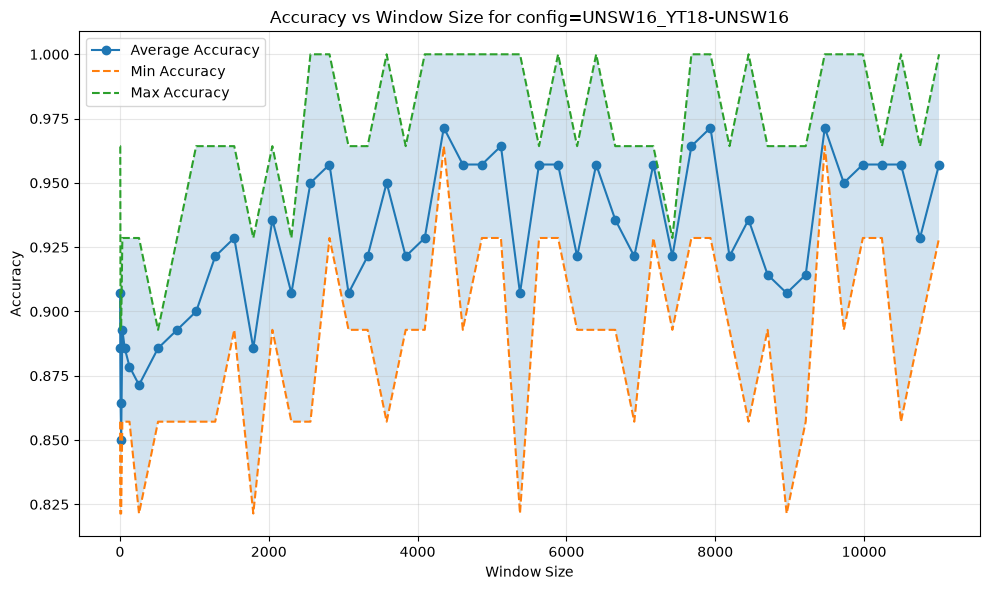

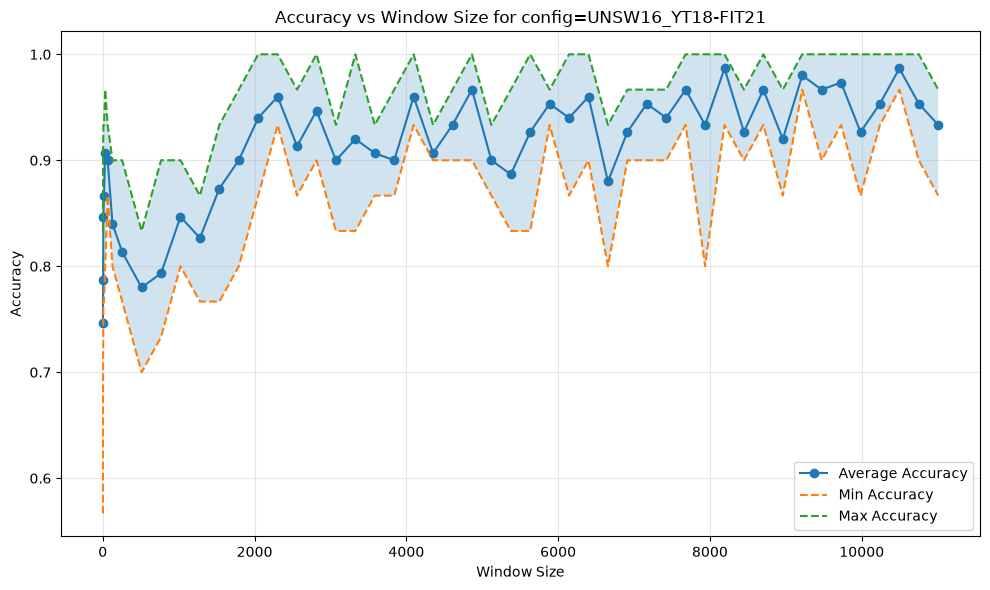

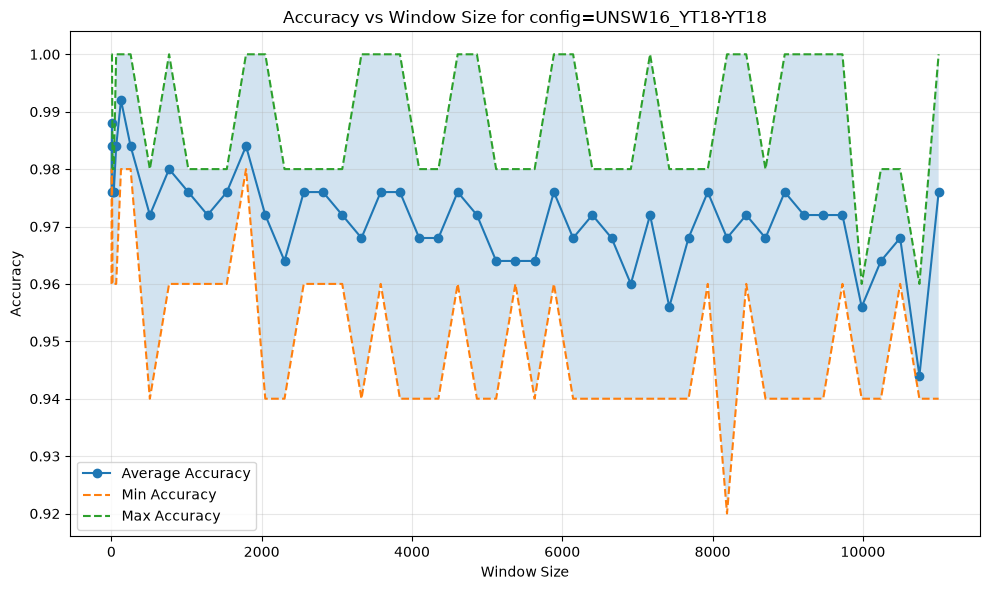

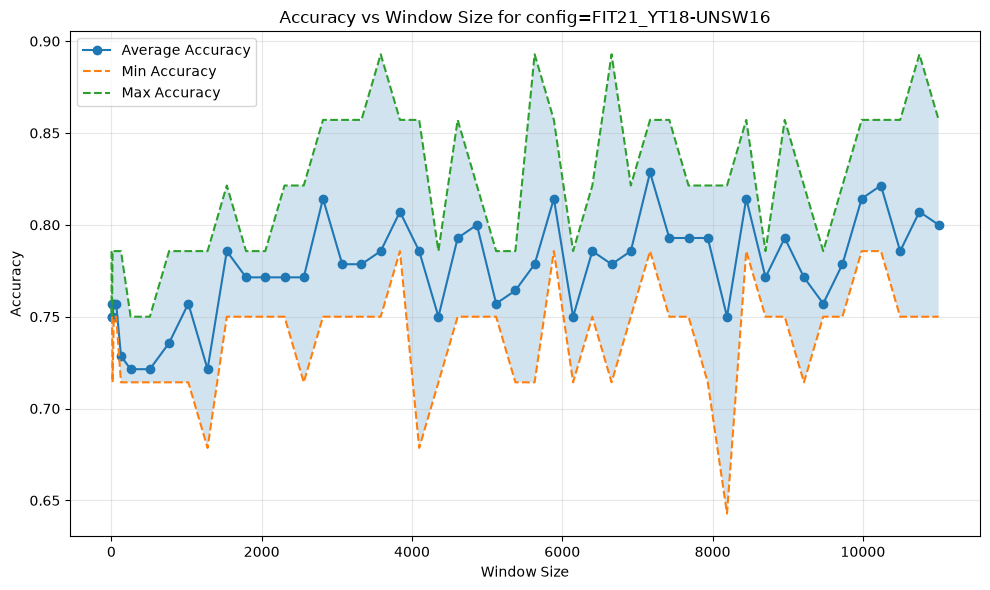

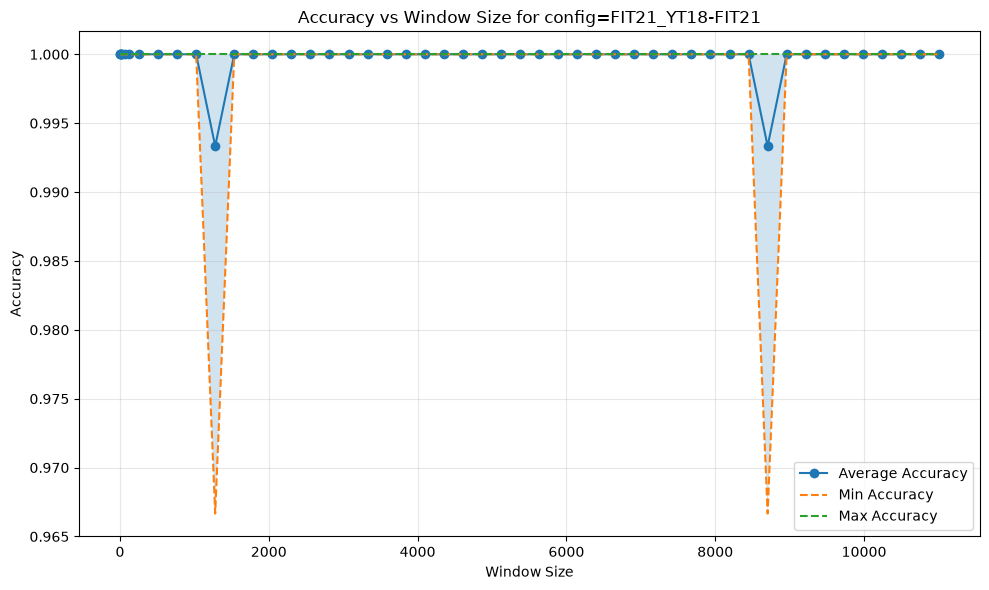

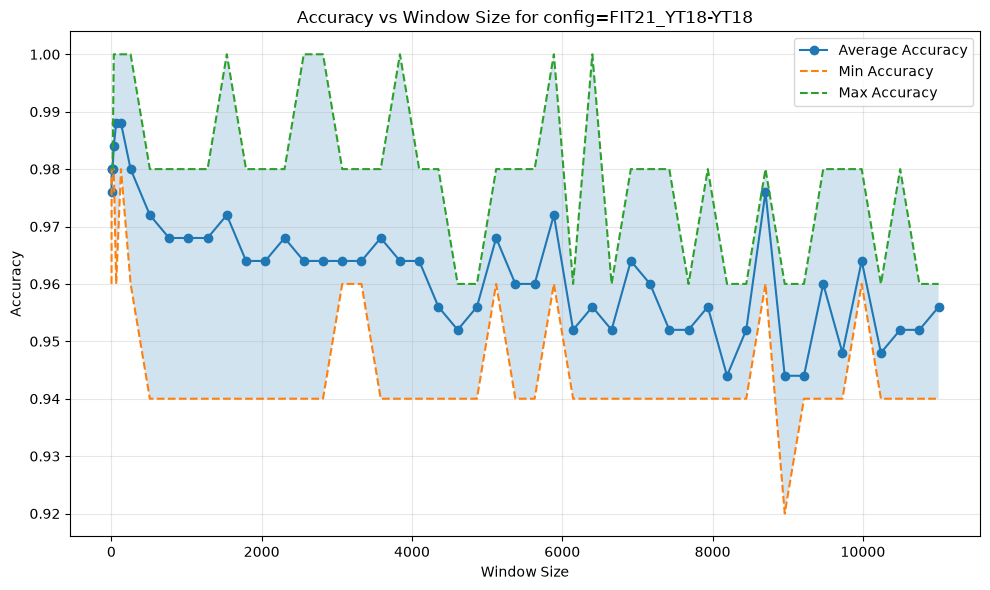

In [20]:
for config in all_configs:
    config_path = PERFORMANCE_EXPORT_FOLDER + "/" + config
    
    metrics1_df = pd.DataFrame(all_configs[config]["metrics_1"])
    evaluations1_df = pd.concat(all_configs[config]["evaluations_1"], ignore_index=True)

    metrics2_df = pd.DataFrame(all_configs[config]["metrics_2"])
    evaluations2_df = pd.concat(all_configs[config]["evaluations_2"], ignore_index=True)

    metrics3_df = pd.DataFrame(all_configs[config]["metrics_3"])
    evaluations3_df = pd.concat(all_configs[config]["evaluations_3"], ignore_index=True)

    save_metric_and_plotting(config_path=config_path, metrics_df=metrics1_df, evaluations_df=evaluations1_df, suffix=DATASET_NAME[FEATURES_FOLDER_1], all_configs=all_configs)
    save_metric_and_plotting(config_path=config_path, metrics_df=metrics2_df, evaluations_df=evaluations2_df, suffix=DATASET_NAME[FEATURES_FOLDER_2], all_configs=all_configs)
    save_metric_and_plotting(config_path=config_path, metrics_df=metrics3_df, evaluations_df=evaluations3_df, suffix=DATASET_NAME[FEATURES_FOLDER_3], all_configs=all_configs)

    

[np.float64(0.9602857142857144),
 np.float64(0.9986666666666666),
 np.float64(0.7488800000000001)]

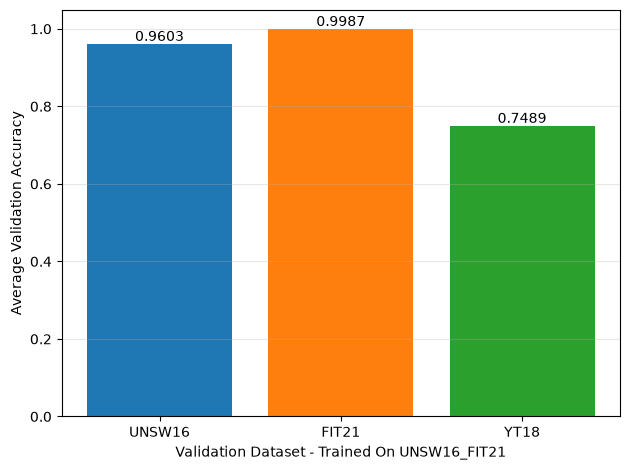

[np.float64(0.9264285714285714),
 np.float64(0.9103999999999999),
 np.float64(0.9719999999999999)]

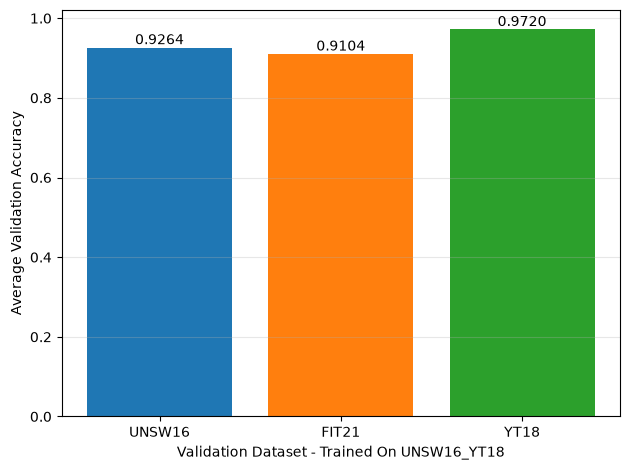

[np.float64(0.7751428571428569),
 np.float64(0.9997333333333333),
 np.float64(0.9632)]

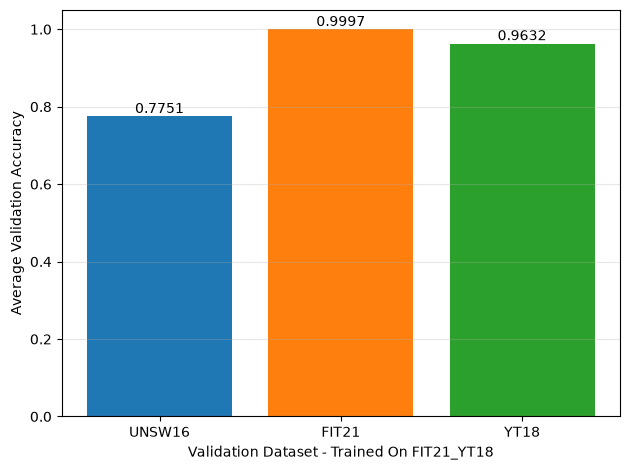

In [21]:
Path("imgs").mkdir(parents=True, exist_ok=True)
DATASET_ORDER = ["UNSW16", "FIT21", "YT18"]
colors = plt.cm.tab10(range(len(DATASET_ORDER)))
for combo in dataset_combos:
    trained_dataset = [DATASET_NAME[dataset] for dataset in combo]
    config_key = "_".join(trained_dataset)

    metrics1_df = pd.DataFrame(all_configs[config_key]["metrics_1"])
    metrics2_df = pd.DataFrame(all_configs[config_key]["metrics_2"])
    metrics3_df = pd.DataFrame(all_configs[config_key]["metrics_3"])

    avg_across_all_window_1 = metrics1_df.groupby("window")["accuracy"].mean().mean()
    avg_across_all_window_2 = metrics2_df.groupby("window")["accuracy"].mean().mean()   
    avg_across_all_window_3 = metrics3_df.groupby("window")["accuracy"].mean().mean()

    avg_accuracies = [avg_across_all_window_1, avg_across_all_window_2, avg_across_all_window_3]
    display(avg_accuracies)
    bars = plt.bar(
        DATASET_ORDER,
        avg_accuracies,
        color=colors
    )

    # Add accuracy value above each bar
    for bar, accuracy in zip(
        bars,
        avg_accuracies
    ):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{accuracy:.4f}",
            ha="center",
            va="bottom"
        )
    plt.xlabel(f"Validation Dataset - Trained On {config_key}")
    plt.ylabel("Average Validation Accuracy")

    plt.grid(axis="y", alpha=0.3)
    plt.ylim(
        0,
        max(avg_accuracies) * 1.05
    )
    plt.tight_layout()
    plt.savefig(f"imgs/avg-accuracies-model-trained-{config_key}.png", dpi=300, bbox_inches="tight")
    plt.show()